In [3]:
%pip install pandas numpy matplotlib scikit-learn python-dotenv requests

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


In [5]:
df = pd.read_csv("inventory_demand.csv")

print("✅ Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

✅ Dataset loaded successfully!
Rows: 1525
Columns: 19


,facility_id,facility_name,facility_type,region,facility_capacity,medicine_id,medicine_name,medicine_category,batch_id,quantity_available,expiry_date,storage_temperature,unit_cost,daily_demand,demand_7_days,demand_30_days,demand_90_days,safety_stock,days_until_expiry
0,FAC001,City General Hospital,District Hospital,South,5229,MED001,Paracetamol 500 mg,Analgesic,001-001-B2,1354,2026-10-14,Ambient,2.5,98.24,515,3536,10747,392,-14
1,FAC001,City General Hospital,District Hospital,South,5229,MED002,Amoxicillin 500 mg,Antibiotic,002-001-B1,483,2026-12-25,Ambient,5.8,93.30,774,2515,6391,559,58
2,FAC001,City General Hospital,District Hospital,South,5229,MED003,Oral Rehydration Salts,Essential Medicine,003-001-B3,1052,2027-11-12,Ambient,1.2,52.54,466,1180,3967,157,380
3,FAC001,City General Hospital,District Hospital,South,5229,MED004,Cetirizine 10 mg,Antihistamine,004-001-B2,1824,2028-04-09,Ambient,1.8,33.88,230,945,3630,135,529
4,FAC001,City General Hospital,District Hospital,South,5229,MED005,Metformin 500 mg,Antidiabetic,005-001-B1,507,2027-03-24,Ambient,2.1,38.18,299,1086,2829,229,147


In [6]:

#inspecting the dataset
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset dimensions: (1525, 19)

Column names:
['facility_id', 'facility_name', 'facility_type', 'region', 'facility_capacity', 'medicine_id', 'medicine_name', 'medicine_category', 'batch_id', 'quantity_available', 'expiry_date', 'storage_temperature', 'unit_cost', 'daily_demand', 'demand_7_days', 'demand_30_days', 'demand_90_days', 'safety_stock', 'days_until_expiry']

Data types:


,Data Type
facility_id,str
facility_name,str
facility_type,str
region,str
facility_capacity,int64
medicine_id,str
medicine_name,str
medicine_category,str
batch_id,str
quantity_available,int64



Missing values:


,Missing Values
facility_id,0
facility_name,0
facility_type,0
region,0
facility_capacity,0
medicine_id,0
medicine_name,0
medicine_category,0
batch_id,0
quantity_available,0



Duplicate rows: 0


In [7]:
#verify requirewd columns
required_columns = [
    "facility_id",
    "facility_name",
    "facility_type",
    "region",
    "facility_capacity",
    "medicine_id",
    "medicine_name",
    "medicine_category",
    "batch_id",
    "quantity_available",
    "expiry_date",
    "storage_temperature",
    "unit_cost",
    "daily_demand",
    "demand_7_days",
    "demand_30_days",
    "demand_90_days",
    "safety_stock",
    "days_until_expiry"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("❌ Missing columns:", missing_columns)
else:
    print("✅ All required columns are present!")

✅ All required columns are present!


In [8]:
#cleaning the dataset
#  Convert expiry date into datetime format
df["expiry_date"] = pd.to_datetime(
    df["expiry_date"],
    errors="coerce"
)

# Convert numerical columns
numeric_columns = [
    "facility_capacity",
    "quantity_available",
    "unit_cost",
    "daily_demand",
    "demand_7_days",
    "demand_30_days",
    "demand_90_days",
    "safety_stock",
    "days_until_expiry"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("✅ Data types cleaned!")

display(df.head())

✅ Data types cleaned!


,facility_id,facility_name,facility_type,region,facility_capacity,medicine_id,medicine_name,medicine_category,batch_id,quantity_available,expiry_date,storage_temperature,unit_cost,daily_demand,demand_7_days,demand_30_days,demand_90_days,safety_stock,days_until_expiry
0,FAC001,City General Hospital,District Hospital,South,5229,MED001,Paracetamol 500 mg,Analgesic,001-001-B2,1354,2026-10-14,Ambient,2.5,98.24,515,3536,10747,392,-14
1,FAC001,City General Hospital,District Hospital,South,5229,MED002,Amoxicillin 500 mg,Antibiotic,002-001-B1,483,2026-12-25,Ambient,5.8,93.30,774,2515,6391,559,58
2,FAC001,City General Hospital,District Hospital,South,5229,MED003,Oral Rehydration Salts,Essential Medicine,003-001-B3,1052,2027-11-12,Ambient,1.2,52.54,466,1180,3967,157,380
3,FAC001,City General Hospital,District Hospital,South,5229,MED004,Cetirizine 10 mg,Antihistamine,004-001-B2,1824,2028-04-09,Ambient,1.8,33.88,230,945,3630,135,529
4,FAC001,City General Hospital,District Hospital,South,5229,MED005,Metformin 500 mg,Antidiabetic,005-001-B1,507,2027-03-24,Ambient,2.1,38.18,299,1086,2829,229,147


In [9]:
#7
print("Missing values before handling:")
display(df.isnull().sum().to_frame("Missing Values"))

print(
    "Negative inventory records:",
    (df["quantity_available"] < 0).sum()
)

print(
    "Invalid expiry dates:",
    df["expiry_date"].isna().sum()
)

Missing values before handling:


,Missing Values
facility_id,0
facility_name,0
facility_type,0
region,0
facility_capacity,0
medicine_id,0
medicine_name,0
medicine_category,0
batch_id,0
quantity_available,0


Negative inventory records: 0
Invalid expiry dates: 0


In [10]:
#8 calculate days until expiry
today = pd.Timestamp.today().normalize()

df["days_until_expiry"] = (
    df["expiry_date"] - today
).dt.days

df["is_expired"] = (
    df["days_until_expiry"] < 0
)

df["expires_within_30_days"] = (
    (df["days_until_expiry"] >= 0)
    & (df["days_until_expiry"] <= 30)
)

display(
    df[[
        "facility_name",
        "medicine_name",
        "batch_id",
        "quantity_available",
        "expiry_date",
        "days_until_expiry",
        "is_expired",
        "expires_within_30_days"
    ]].head(10)
)

,facility_name,medicine_name,batch_id,quantity_available,expiry_date,days_until_expiry,is_expired,expires_within_30_days
0,City General Hospital,Paracetamol 500 mg,001-001-B2,1354,2026-10-14,-15,True,False
1,City General Hospital,Amoxicillin 500 mg,002-001-B1,483,2026-12-25,57,False,False
2,City General Hospital,Oral Rehydration Salts,003-001-B3,1052,2027-11-12,379,False,False
3,City General Hospital,Cetirizine 10 mg,004-001-B2,1824,2028-04-09,528,False,False
4,City General Hospital,Metformin 500 mg,005-001-B1,507,2027-03-24,146,False,False
5,City General Hospital,Amlodipine 5 mg,006-001-B1,167,2028-10-16,718,False,False
6,City General Hospital,Omeprazole 20 mg,007-001-B1,608,2027-04-09,162,False,False
7,City General Hospital,Azithromycin 250 mg,008-001-B1,868,2028-07-08,618,False,False
8,City General Hospital,Ibuprofen 200 mg,009-001-B1,296,2028-02-03,462,False,False
9,City General Hospital,Iron and Folic Acid,010-001-B3,770,2028-10-13,715,False,False


In [11]:
#9 expired stock will be excluded 

# 1. Ensure the required columns have the correct types
df["expiry_date"] = pd.to_datetime(
    df["expiry_date"],
    errors="coerce"
)

df["quantity_available"] = pd.to_numeric(
    df["quantity_available"],
    errors="coerce"
)

# 2. Calculate days until expiry
today = pd.Timestamp.today().normalize()

df["days_until_expiry"] = (
    df["expiry_date"] - today
).dt.days

# 3. Identify expired batches
df["is_expired"] = df["days_until_expiry"] < 0

# 4. Create the data-quality flag FIRST
df["data_quality_issue"] = (
    df["facility_id"].isna()
    | df["medicine_id"].isna()
    | df["quantity_available"].isna()
    | df["expiry_date"].isna()
    | (df["quantity_available"] < 0)
)

# 5. Calculate usable stock
df["usable_quantity"] = np.where(
    (~df["is_expired"])
    & (~df["data_quality_issue"]),
    df["quantity_available"].clip(lower=0),
    0
)

# 6. Display results
print("Total rows:", len(df))
print("Rows needing review:", df["data_quality_issue"].sum())
print("Expired batches:", df["is_expired"].sum())
print("Total usable quantity:", df["usable_quantity"].sum())

display(
    df[[
        "facility_name",
        "medicine_name",
        "batch_id",
        "quantity_available",
        "expiry_date",
        "days_until_expiry",
        "data_quality_issue",
        "usable_quantity"
    ]].head(10)
)


Total rows: 1525
Rows needing review: 0
Expired batches: 48
Total usable quantity: 1575354


,facility_name,medicine_name,batch_id,quantity_available,expiry_date,days_until_expiry,data_quality_issue,usable_quantity
0,City General Hospital,Paracetamol 500 mg,001-001-B2,1354,2026-10-14,-15,False,0
1,City General Hospital,Amoxicillin 500 mg,002-001-B1,483,2026-12-25,57,False,483
2,City General Hospital,Oral Rehydration Salts,003-001-B3,1052,2027-11-12,379,False,1052
3,City General Hospital,Cetirizine 10 mg,004-001-B2,1824,2028-04-09,528,False,1824
4,City General Hospital,Metformin 500 mg,005-001-B1,507,2027-03-24,146,False,507
5,City General Hospital,Amlodipine 5 mg,006-001-B1,167,2028-10-16,718,False,167
6,City General Hospital,Omeprazole 20 mg,007-001-B1,608,2027-04-09,162,False,608
7,City General Hospital,Azithromycin 250 mg,008-001-B1,868,2028-07-08,618,False,868
8,City General Hospital,Ibuprofen 200 mg,009-001-B1,296,2028-02-03,462,False,296
9,City General Hospital,Iron and Folic Acid,010-001-B3,770,2028-10-13,715,False,770


In [12]:
df["potential_surplus"] = (
    df["usable_quantity"]
    - df["demand_7_days"]
    - df["safety_stock"]
).clip(lower=0)

df["potential_shortage"] = (
    df["demand_7_days"]
    + df["safety_stock"]
    - df["usable_quantity"]
).clip(lower=0)

print(
    "Potential surplus:",
    df["potential_surplus"].sum()
)

print(
    "Potential shortage:",
    df["potential_shortage"].sum()
)

display(
    df[[
        "facility_name",
        "medicine_name",
        "batch_id",
        "usable_quantity",
        "demand_7_days",
        "safety_stock",
        "potential_surplus",
        "potential_shortage"
    ]].head(10)
)

Potential surplus: 728397
Potential shortage: 309888


,facility_name,medicine_name,batch_id,usable_quantity,demand_7_days,safety_stock,potential_surplus,potential_shortage
0,City General Hospital,Paracetamol 500 mg,001-001-B2,0,515,392,0,907
1,City General Hospital,Amoxicillin 500 mg,002-001-B1,483,774,559,0,850
2,City General Hospital,Oral Rehydration Salts,003-001-B3,1052,466,157,429,0
3,City General Hospital,Cetirizine 10 mg,004-001-B2,1824,230,135,1459,0
4,City General Hospital,Metformin 500 mg,005-001-B1,507,299,229,0,21
5,City General Hospital,Amlodipine 5 mg,006-001-B1,167,648,491,0,972
6,City General Hospital,Omeprazole 20 mg,007-001-B1,608,407,639,0,438
7,City General Hospital,Azithromycin 250 mg,008-001-B1,868,319,287,262,0
8,City General Hospital,Ibuprofen 200 mg,009-001-B1,296,652,911,0,1267
9,City General Hospital,Iron and Folic Acid,010-001-B3,770,389,654,0,273


In [13]:
#11
# Facility and medicine details that should remain constant
facility_medicine = (
    df.groupby(
        [
            "facility_id",
            "facility_name",
            "region",
            "medicine_id",
            "medicine_name"
        ],
        as_index=False
    )
    .agg(
        usable_quantity=("usable_quantity", "sum"),
        total_recorded_quantity=("quantity_available", "sum"),
        demand_7_days=("demand_7_days", "max"),
        safety_stock=("safety_stock", "max")
    )
)

facility_medicine["potential_surplus"] = (
    facility_medicine["usable_quantity"]
    - facility_medicine["demand_7_days"]
    - facility_medicine["safety_stock"]
).clip(lower=0)

facility_medicine["potential_shortage"] = (
    facility_medicine["demand_7_days"]
    + facility_medicine["safety_stock"]
    - facility_medicine["usable_quantity"]
).clip(lower=0)

display(facility_medicine.head(10))

,facility_id,facility_name,region,medicine_id,medicine_name,usable_quantity,total_recorded_quantity,demand_7_days,safety_stock,potential_surplus,potential_shortage
0,FAC001,City General Hospital,South,MED001,Paracetamol 500 mg,0,1354,515,392,0,907
1,FAC001,City General Hospital,South,MED002,Amoxicillin 500 mg,483,483,774,559,0,850
2,FAC001,City General Hospital,South,MED003,Oral Rehydration Salts,1052,1052,466,157,429,0
3,FAC001,City General Hospital,South,MED004,Cetirizine 10 mg,1824,1824,230,135,1459,0
4,FAC001,City General Hospital,South,MED005,Metformin 500 mg,507,507,299,229,0,21
5,FAC001,City General Hospital,South,MED006,Amlodipine 5 mg,167,167,648,491,0,972
6,FAC001,City General Hospital,South,MED007,Omeprazole 20 mg,608,608,407,639,0,438
7,FAC001,City General Hospital,South,MED008,Azithromycin 250 mg,868,868,319,287,262,0
8,FAC001,City General Hospital,South,MED009,Ibuprofen 200 mg,296,296,652,911,0,1267
9,FAC001,City General Hospital,South,MED010,Iron and Folic Acid,770,770,389,654,0,273


In [14]:
#12
surplus_df = (
    facility_medicine[
        facility_medicine["potential_surplus"] > 0
    ]
    .sort_values(
        "potential_surplus",
        ascending=False
    )
)

display(surplus_df.head(15))

,facility_id,facility_name,region,medicine_id,medicine_name,usable_quantity,total_recorded_quantity,demand_7_days,safety_stock,potential_surplus,potential_shortage
520,FAC021,Silverline Hospital,North,MED021,Loratadine 10 mg,2148,2148,53,53,2042,0
466,FAC019,Cedar Grove Hospital,East,MED017,Chlorhexidine Solution,2191,2191,74,76,2041,0
872,FAC035,Willowbrook Hospital,North,MED023,Omeprazole Suspension,2193,2193,107,57,2029,0
10,FAC001,City General Hospital,South,MED011,Human Insulin Injection,2139,2139,75,58,2006,0
276,FAC012,Unity Medical Centre,West,MED002,Amoxicillin 500 mg,2087,2087,57,43,1987,0
1259,FAC051,Palm Grove Health Centre,East,MED010,Iron and Folic Acid,2067,2067,50,41,1976,0
583,FAC024,Redwood Community Hospital,North,MED009,Ibuprofen 200 mg,2193,2193,111,110,1972,0
992,FAC040,Gardenview Clinic,North,MED018,Vitamin A Capsules,2160,2160,114,102,1944,0
36,FAC002,Northside Clinic,South,MED012,Tetanus Vaccine,2168,2168,120,105,1943,0
1342,FAC054,Crown Medical Centre,South,MED018,Vitamin A Capsules,2109,2109,89,89,1931,0


In [15]:
#13 
shortage_df=(
    facility_medicine[
        facility_medicine["potential_shortage"]>0
    ].sort_values("potential_shortage",ascending=False)
)
display(shortage_df.head(15))

,facility_id,facility_name,region,medicine_id,medicine_name,usable_quantity,total_recorded_quantity,demand_7_days,safety_stock,potential_surplus,potential_shortage
453,FAC019,Cedar Grove Hospital,East,MED004,Cetirizine 10 mg,191,191,958,1005,0,1772
96,FAC004,Greenfield Community Hospital,Central,MED022,Losartan 50 mg,201,201,837,1106,0,1742
148,FAC006,Lakeview Hospital,East,MED024,Amikacin Injection,10,10,780,908,0,1678
560,FAC023,Brookside Medical Centre,South,MED011,Human Insulin Injection,16,16,774,909,0,1667
956,FAC039,Summit Medical Centre,East,MED007,Omeprazole 20 mg,223,223,794,1073,0,1644
275,FAC012,Unity Medical Centre,West,MED001,Paracetamol 500 mg,20,20,828,832,0,1640
400,FAC017,Oakwood Clinic,East,MED001,Paracetamol 500 mg,156,156,734,1055,0,1633
54,FAC003,Riverside Medical Centre,Central,MED005,Metformin 500 mg,283,283,893,984,0,1594
1496,FAC060,Golden Fields Hospital,Central,MED022,Losartan 50 mg,120,120,803,844,0,1527
377,FAC016,Valley Community Hospital,East,MED003,Oral Rehydration Salts,391,391,907,947,0,1463


Top 10 potential surplus records


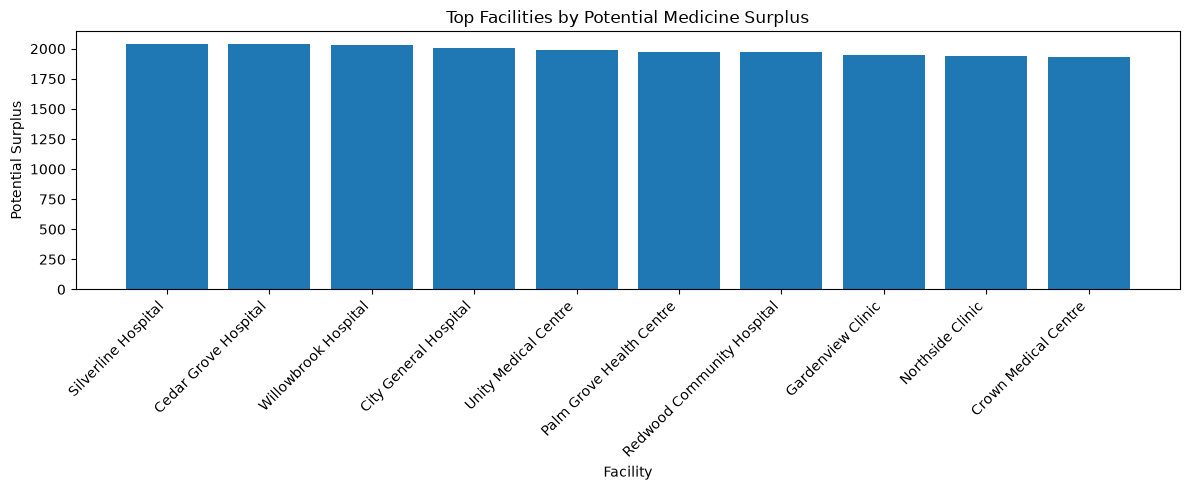

In [16]:
#14 visualise surplus
print("Top 10 potential surplus records")

top_surplus = surplus_df.head(10)

plt.figure(figsize=(12, 5))
plt.bar(
    top_surplus["facility_name"],
    top_surplus["potential_surplus"]
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Facility")
plt.ylabel("Potential Surplus")
plt.title("Top Facilities by Potential Medicine Surplus")
plt.tight_layout()
plt.show()

Top 10 potential shortage records


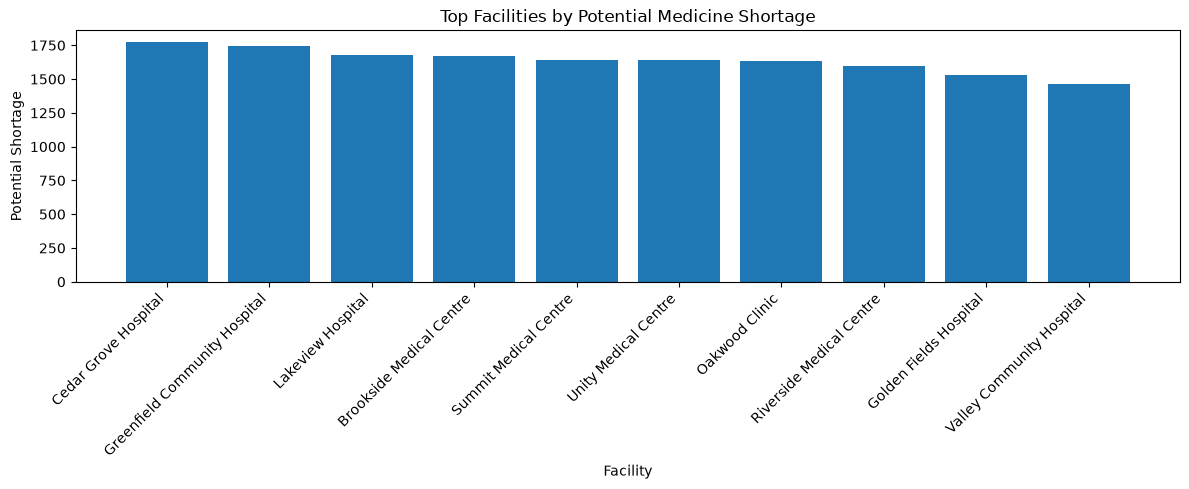

In [17]:
#15 visualise shortages
print("Top 10 potential shortage records")

top_shortage = shortage_df.head(10)

plt.figure(figsize=(12, 5))
plt.bar(
    top_shortage["facility_name"],
    top_shortage["potential_shortage"]
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Facility")
plt.ylabel("Potential Shortage")
plt.title("Top Facilities by Potential Medicine Shortage")
plt.tight_layout()
plt.show()

In [18]:
# checking if we have historical data for mlmodel
print("Rows available:", len(df))
print(
    "Unique facilities:",
    df["facility_id"].nunique()
)
print(
    "Unique medicines:",
    df["medicine_id"].nunique()
)

print("\nDemand columns:")
display(
    df[
        [
            "daily_demand",
            "demand_7_days",
            "demand_30_days",
            "demand_90_days"
        ]
    ].describe()
)

Rows available: 1525
Unique facilities: 61
Unique medicines: 25

Demand columns:


,daily_demand,demand_7_days,demand_30_days,demand_90_days
count,1525.000000,1525.000000,1525.000000,1525.000000
mean,55.532577,396.316066,1643.891148,4894.363934
std,27.575589,210.592190,851.656267,2459.469364
min,6.050000,37.000000,168.000000,541.000000
25%,32.420000,220.000000,946.000000,2859.000000
50%,55.400000,388.000000,1587.000000,4807.000000
75%,77.630000,547.000000,2294.000000,6751.000000
max,125.720000,958.000000,3788.000000,10864.000000


In [19]:
#load transport routes
routes = pd.read_csv("transport_routes.csv")

print("✅ Transport routes loaded!")
print("Rows:", routes.shape[0])
print("Columns:", routes.shape[1])

display(routes.head())

✅ Transport routes loaded!
Rows: 200
Columns: 5


,source_facility_id,destination_facility_id,distance_km,transport_cost,transport_time_hours
0,FAC001,FAC009,137.86,853.38,4.31
1,FAC001,FAC059,5.49,111.53,0.45
2,FAC001,FAC008,84.67,661.33,2.72
3,FAC001,FAC040,142.92,1051.24,5.12
4,FAC002,FAC061,133.24,864.66,3.34


In [20]:
required_route_columns = [
    "source_facility_id",
    "destination_facility_id",
    "distance_km",
    "transport_cost",
    "transport_time_hours"
]

missing_route_columns = [
    col for col in required_route_columns
    if col not in routes.columns
]

if missing_route_columns:
    print(
        "❌ Missing route columns:",
        missing_route_columns
    )
else:
    print("✅ Route columns are present!")

✅ Route columns are present!


In [21]:
surplus_candidates = facility_medicine[
    facility_medicine["potential_surplus"] > 0
].copy()

shortage_candidates = facility_medicine[
    facility_medicine["potential_shortage"] > 0
].copy()

candidates = surplus_candidates.merge(
    shortage_candidates,
    on="medicine_id",
    suffixes=("_source", "_destination")
)

candidates = candidates[
    candidates["facility_id_source"] != candidates["facility_id_destination"]
].copy()

candidates = candidates.merge(
    routes,
    left_on=["facility_id_source", "facility_id_destination"],
    right_on=["source_facility_id", "destination_facility_id"],
    how="inner"
)

candidates["maximum_possible_transfer"] = np.minimum(
    candidates["potential_surplus_source"],
    candidates["potential_shortage_destination"]
)

print("Feasible transfer candidates:", len(candidates))
display(candidates.head(10))

Feasible transfer candidates: 1192


,facility_id_source,facility_name_source,region_source,medicine_id,medicine_name_source,usable_quantity_source,total_recorded_quantity_source,demand_7_days_source,safety_stock_source,potential_surplus_source,...,demand_7_days_destination,safety_stock_destination,potential_surplus_destination,potential_shortage_destination,source_facility_id,destination_facility_id,distance_km,transport_cost,transport_time_hours,maximum_possible_transfer
0,FAC001,City General Hospital,South,MED004,Cetirizine 10 mg,1824,1824,230,135,1459,...,537,438,0,56,FAC001,FAC009,137.86,853.38,4.31,56
1,FAC001,City General Hospital,South,MED004,Cetirizine 10 mg,1824,1824,230,135,1459,...,671,714,0,643,FAC001,FAC059,5.49,111.53,0.45,643
2,FAC001,City General Hospital,South,MED008,Azithromycin 250 mg,868,868,319,287,262,...,310,230,0,456,FAC001,FAC040,142.92,1051.24,5.12,262
3,FAC001,City General Hospital,South,MED008,Azithromycin 250 mg,868,868,319,287,262,...,748,683,0,1431,FAC001,FAC059,5.49,111.53,0.45,262
4,FAC001,City General Hospital,South,MED011,Human Insulin Injection,2139,2139,75,58,2006,...,738,398,0,98,FAC001,FAC008,84.67,661.33,2.72,98
5,FAC001,City General Hospital,South,MED011,Human Insulin Injection,2139,2139,75,58,2006,...,626,651,0,1277,FAC001,FAC059,5.49,111.53,0.45,1277
6,FAC001,City General Hospital,South,MED012,Tetanus Vaccine,1852,1852,105,107,1640,...,554,762,0,944,FAC001,FAC009,137.86,853.38,4.31,944
7,FAC001,City General Hospital,South,MED012,Tetanus Vaccine,1852,1852,105,107,1640,...,556,754,0,252,FAC001,FAC040,142.92,1051.24,5.12,252
8,FAC001,City General Hospital,South,MED013,Oxytocin Injection,685,685,152,106,427,...,697,638,0,1058,FAC001,FAC008,84.67,661.33,2.72,427
9,FAC001,City General Hospital,South,MED014,Salbutamol Inhaler,1596,1596,422,363,811,...,574,844,0,398,FAC001,FAC009,137.86,853.38,4.31,398


In [22]:
%pip install python-dotenv requests

Note: you may need to restart the kernel to use updated packages.


In [23]:
from pathlib import Path
from dotenv import load_dotenv
import os

env_path = Path.cwd() / ".env"

load_dotenv(dotenv_path=env_path, override=True)

QPIAI_API_KEY = os.getenv("QPIAI_API_KEY")

if QPIAI_API_KEY:
    print("✅ API key loaded successfully!")
else:
    print("❌ API key not found. Check your .env file location and contents.")

✅ API key loaded successfully!


In [24]:
import requests

url = "https://opt-server.qpiai.tech/api/problems/create"

try:
    response = requests.post(
        url,
        headers={
            "Authorization": f"Bearer {QPIAI_API_KEY}",
            "Content-Type": "application/json"
        },
        json={},
        timeout=20
    )

    print("HTTP status:", response.status_code)

    if response.status_code == 401:
        print("Token missing or invalid.")
    elif response.status_code == 403:
        print("Access denied; check permissions.")
    elif response.status_code == 404:
        print("Endpoint not found; check the current API documentation.")
    else:
        print("Server responded. Check the API docs for this status.")

except requests.RequestException as e:
    print("Connection error:", type(e).__name__)

HTTP status: 401
Token missing or invalid.


In [25]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)
QPIAI_API_KEY = os.getenv("QPIAI_API_KEY")

print("Token loaded:", bool(QPIAI_API_KEY))
print("Token length:", len(QPIAI_API_KEY) if QPIAI_API_KEY else 0)

Token loaded: True
Token length: 64


In [26]:
import requests

url = "https://opt-server.qpiai.tech/api/problems/create"

response = requests.post(
    url,
    headers={
        "X-Secret-Token": QPIAI_API_KEY,
        "Content-Type": "application/json"
    },
    json={},
    timeout=20
)

print("HTTP status:", response.status_code)

HTTP status: 400


In [27]:
print("HTTP status:", response.status_code)

try:
    data = response.json()
    print("Error details:", data.get("error", "No error field returned"))
except ValueError:
    print("The server did not return JSON.")

HTTP status: 400
Error details: method must be one of 'QUBO', 'HUBO', 'MILP', or 'maximumCut'


In [28]:
print("Status:", response.status_code)
print("Server error:", response.text[:500])

Status: 400
Server error: {"error":"method must be one of 'QUBO', 'HUBO', 'MILP', or 'maximumCut'"}


In [29]:
import requests

url = "https://opt-server.qpiai.tech/api/problems/create"

response = requests.post(
    url,
    headers={
        "X-Secret-Token": QPIAI_API_KEY,
        "Content-Type": "application/json"
    },
    json={"method": "MILP"},
    timeout=20
)

print("HTTP status:", response.status_code)
print("Response:", response.text[:500])

HTTP status: 400
Response: {"error":"milp_model_storage_id is required for MILP"}


In [30]:
print("Status:", response.status_code)
print("Error:", response.text[:500])

Status: 400
Error: {"error":"milp_model_storage_id is required for MILP"}


In [31]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\PRANAV\anaconda3\python.exe
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [32]:
%pip show qpia-opt

Note: you may need to restart the kernel to use updated packages.


In [33]:
%pip install qpiai-opt

Note: you may need to restart the kernel to use updated packages.


In [34]:
import sys
print("Python:", sys.version)
print("Environment:", sys.executable)

%pip show qpia-opt

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Environment: c:\Users\PRANAV\anaconda3\python.exe
Note: you may need to restart the kernel to use updated packages.


In [2]:
from qpia_opt.opt_modeller import (
    Binary, Continuous, Indicator, Integer, Model
)

print("MILP modeller is ready!")

ModuleNotFoundError: No module named 'qpia_opt'

In [3]:
%pip install qpiai-opt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from qpia_opt.opt_modeller import (
    Binary, Continuous, Indicator, Integer, Model
)

print("MILP modeller is ready!")

In [2]:
import importlib.util
import importlib.metadata as metadata

print("Package version:", metadata.version("qpiai-opt"))
print("Module found:", importlib.util.find_spec("qpiai_opt"))
print("Modeller found:", importlib.util.find_spec("qpiai_opt.opt_modeller"))

Package version: 0.0.9
Module found: ModuleSpec(name='qpiai_opt', loader=<_frozen_importlib_external.SourceFileLoader object at 0x0000026BC850C110>, origin='c:\\Users\\PRANAV\\anaconda3\\Lib\\site-packages\\qpiai_opt\\__init__.py', submodule_search_locations=['c:\\Users\\PRANAV\\anaconda3\\Lib\\site-packages\\qpiai_opt'])
Modeller found: ModuleSpec(name='qpiai_opt.opt_modeller', loader=<_frozen_importlib_external.SourceFileLoader object at 0x0000026BC850C1D0>, origin='c:\\Users\\PRANAV\\anaconda3\\Lib\\site-packages\\qpiai_opt\\opt_modeller\\__init__.py', submodule_search_locations=['c:\\Users\\PRANAV\\anaconda3\\Lib\\site-packages\\qpiai_opt\\opt_modeller'])


In [3]:
from qpiai_opt.opt_modeller import (
    Binary,
    Continuous,
    Indicator,
    Integer,
    Model
)

print("QpiAI MILP modeller is ready!")

QpiAI MILP modeller is ready!


In [4]:
from qpiai_opt.opt_modeller import Binary, Continuous, Integer, Model

# Create a small test optimization problem
model = Model("MediShare_Test")

# Decision variable: number of medicine units to transfer
transfer = Integer("transfer", 0, 10)

# Minimize the number of units transferred for this test
model.minimize(transfer)

# Require at least 5 units to be transferred
model.add_constraint(transfer >= 5, label="minimum_transfer")

# Validate the model
problem_class = model.validate("MILP")

print("Model validated successfully!")
print("Problem class:", problem_class)

Model validated successfully!
Problem class: MILP


In [5]:
print("df:", "df" in globals())
print("facility_medicine:", "facility_medicine" in globals())
print("routes:", "routes" in globals())
print("candidates:", "candidates" in globals())

df: False
facility_medicine: False
routes: False
candidates: False


In [7]:
import os
print("Current folder:", os.getcwd())
print("Files in this folder:")
print(os.listdir())

Current folder: c:\Users\PRANAV\OneDrive\Desktop\hackathon
Files in this folder:
['.env', '.venv', 'edit.ipynb', 'inventory_demand.csv', 'medishare_ai_synthetic_dataset.csv', 'ofb.py', 'transport_routes.csv']


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("medishare_ai_synthetic_dataset.csv")

print("Dataset loaded:", df.shape)
display(df.head())

In [10]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (2000, 17)

Columns:
['facility_id', 'facility_name', 'medicine_id', 'medicine_name', 'batch_id', 'quantity_available', 'expiry_date', 'daily_demand', 'safety_stock', 'storage_temperature', 'facility_capacity', 'destination_facility', 'transport_distance_km', 'transport_cost', 'surplus_quantity', 'shortage_quantity', 'recommended_transfer_quantity']


In [11]:
import os

print([f for f in os.listdir() if f.endswith(".csv")])

['inventory_demand.csv', 'medishare_ai_synthetic_dataset.csv', 'transport_routes.csv']


In [ ]:
print("Dataset rows:", len(df))
print("Missing values:")
print(df.isnull().sum())

print("\nSample records:")
display(df.head(5))

In [ ]:
print("Unique facilities:", df["facility_id"].nunique())
print("Unique medicines:", df["medicine_id"].nunique())
print("Potential surplus:", df["surplus_quantity"].sum())
print("Potential shortage:", df["shortage_quantity"].sum())
print("Existing recommended transfers:",
      df["recommended_transfer_quantity"].sum())

print("\nSample transfer destinations:")
display(
    df[[
        "facility_id",
        "medicine_id",
        "destination_facility",
        "surplus_quantity",
        "shortage_quantity",
        "transport_cost",
        "recommended_transfer_quantity"
    ]].head(10)
)

In [14]:

# 1. Check duplicate source-medicine-destination combinations
route_keys = [
    "facility_id",
    "medicine_id",
    "destination_facility"
]

print("Total rows:", len(df))
print("Unique source-medicine-destination combinations:",
      df[route_keys].drop_duplicates().shape[0])

print("Duplicate combinations:",
      df.duplicated(subset=route_keys).sum())

# 2. Count feasible transfer options
feasible = df[
    (df["surplus_quantity"] > 0) &
    (df["shortage_quantity"] > 0) &
    (df["recommended_transfer_quantity"] > 0)
].copy()

print("\nRows with surplus, shortage and a recommended transfer:",
      len(feasible))

# 3. Check whether recommended quantities respect the limits
invalid = df[
    (df["recommended_transfer_quantity"] < 0) |
    (df["recommended_transfer_quantity"] > df["surplus_quantity"]) |
    (df["recommended_transfer_quantity"] > df["shortage_quantity"])
]

print("Rows with invalid transfer quantities:", len(invalid))

# 4. Inspect the most useful candidate rows
display(
    feasible[[
        "facility_id",
        "medicine_id",
        "destination_facility",
        "surplus_quantity",
        "shortage_quantity",
        "transport_distance_km",
        "transport_cost",
        "recommended_transfer_quantity"
    ]].head(10)
)


Total rows: 2000
Unique source-medicine-destination combinations: 1018
Duplicate combinations: 982

Rows with surplus, shortage and a recommended transfer: 972
Rows with invalid transfer quantities: 5


,facility_id,medicine_id,destination_facility,surplus_quantity,shortage_quantity,transport_distance_km,transport_cost,recommended_transfer_quantity
1,FAC001,MED001,FAC027 - Bluebell Health Centre,1176,18,34.31,1077.64,18
6,FAC001,MED004,FAC008 - Central District Hospital,1349,162,123.73,3663.31,162
9,FAC001,MED005,FAC032 - Fairview Hospital,51,717,32.96,974.42,51
10,FAC001,MED006,FAC046 - Ashford Community Clinic,1641,546,41.09,1517.22,546
13,FAC001,MED007,FAC004 - Greenfield Community Hospital,1496,166,16.53,575.44,166
14,FAC001,MED008,FAC009 - Eastgate Health Centre,1753,155,96.36,2657.08,155
16,FAC001,MED009,FAC005 - Sunrise Primary Health Centre,1066,159,15.72,499.32,159
19,FAC001,MED010,FAC013 - Hopewell Clinic,1788,161,12.22,464.77,161
20,FAC001,MED011,FAC046 - Ashford Community Clinic,99,448,41.09,746.08,99
22,FAC001,MED012,FAC031 - Sunset Health Centre,1257,333,44.70,1353.09,333


In [ ]:

invalid = df[
    (df["recommended_transfer_quantity"] < 0) |
    (df["recommended_transfer_quantity"] > df["surplus_quantity"]) |
    (df["recommended_transfer_quantity"] > df["shortage_quantity"])
]

display(invalid[[
    "facility_id",
    "medicine_id",
    "destination_facility",
    "surplus_quantity",
    "shortage_quantity",
    "transport_distance_km",
    "transport_cost",
    "recommended_transfer_quantity"
]])


In [ ]:

duplicate_routes = df[
    df.duplicated(
        subset=["facility_id", "medicine_id", "destination_facility"],
        keep=False
    )
].sort_values(
    ["facility_id", "medicine_id", "destination_facility", "transport_cost"]
)

display(duplicate_routes[[
    "facility_id", "medicine_id", "destination_facility",
    "surplus_quantity", "shortage_quantity",
    "transport_distance_km", "transport_cost",
    "recommended_transfer_quantity"
]].head(15))


In [ ]:

# Compare route duplicates
route_keys = [
    "facility_id",
    "medicine_id",
    "destination_facility"
]

route_summary = df.groupby(route_keys).agg(
    row_count=("facility_id", "size"),
    unique_distances=("transport_distance_km", "nunique"),
    unique_costs=("transport_cost", "nunique"),
    unique_surplus=("surplus_quantity", "nunique"),
    unique_shortage=("shortage_quantity", "nunique"),
    unique_recommendations=("recommended_transfer_quantity", "nunique")
).reset_index()

print("Duplicate route groups:", (route_summary["row_count"] > 1).sum())
print("Groups with multiple transport costs:",
      (route_summary["unique_costs"] > 1).sum())
print("Groups with inconsistent surplus:",
      (route_summary["unique_surplus"] > 1).sum())
print("Groups with inconsistent shortage:",
      (route_summary["unique_shortage"] > 1).sum())

display(route_summary[route_summary["row_count"] > 1].head(10))


In [ ]:

# Keep the cheapest option for each source-medicine-destination
df_clean = (
    df.sort_values("transport_cost")
      .drop_duplicates(
          subset=[
              "facility_id",
              "medicine_id",
              "destination_facility"
          ],
          keep="first"
      )
      .copy()
)

# Keep only rows where a transfer is possible
candidates = df_clean[
    (df_clean["surplus_quantity"] > 0) &
    (df_clean["shortage_quantity"] > 0)
].copy()

# A destination must not be the source facility itself
candidates = candidates[
    ~candidates.apply(
        lambda row: row["destination_facility"].startswith(
            row["facility_id"] + " -"
        ),
        axis=1
    )
].copy()

print("Clean route rows:", len(df_clean))
print("Feasible candidate rows:", len(candidates))
print("Total candidate transport cost:", round(candidates["transport_cost"].sum(), 2))

display(candidates[[
    "facility_id",
    "medicine_id",
    "destination_facility",
    "surplus_quantity",
    "shortage_quantity",
    "transport_cost"
]].head(10))


In [ ]:

from qpiai_opt.opt_modeller import Integer, Model
import inspect

print("Model methods:")
print([m for m in dir(Model) if not m.startswith("_")])

print("\nInteger signature:")
print(inspect.signature(Integer))

print("\nModel constructor:")
print(inspect.signature(Model))


In [ ]:

import inspect
from qpiai_opt.opt_modeller import Model, Integer

for method_name in [
    "add_variable",
    "add_constraint",
    "minimize",
    "validate",
    "to_lp_file"
]:
    method = getattr(Model, method_name)
    print(f"\n{method_name}{inspect.signature(method)}")
    print(inspect.getdoc(method))

print("\nInteger documentation:")
print(inspect.getdoc(Integer))


In [ ]:

import pandas as pd
import numpy as np
from qpiai_opt.opt_modeller import Integer, Model

# ==========================================
# 1. PREPARE THE CANDIDATE ROUTES
# ==========================================

opt_df = candidates.copy().reset_index(drop=True)

# Remove missing or invalid values
opt_df = opt_df.dropna(subset=[
    "facility_id",
    "medicine_id",
    "destination_facility",
    "surplus_quantity",
    "shortage_quantity",
    "transport_cost"
]).copy()

opt_df = opt_df[
    (opt_df["transport_cost"] >= 0) &
    (opt_df["surplus_quantity"] > 0) &
    (opt_df["shortage_quantity"] > 0)
].copy()

# Limit each route's transfer to the smaller of its surplus and shortage
opt_df["transfer_upper_bound"] = np.minimum(
    opt_df["surplus_quantity"],
    opt_df["shortage_quantity"]
).astype(int)

opt_df = opt_df[
    opt_df["transfer_upper_bound"] > 0
].reset_index(drop=True)

print("Candidate routes ready:", len(opt_df))

# ==========================================
# 2. CREATE THE MILP MODEL
# ==========================================

model = Model("MediShare_AI_Transfer_Optimization")

transfer_vars = []

for i, row in opt_df.iterrows():
    variable = Integer(
        f"transfer_{i}",
        0,
        int(row["transfer_upper_bound"])
    )
    model.add_variable(variable)
    transfer_vars.append(variable)

print("Decision variables created:", len(transfer_vars))

# ==========================================
# 3. MINIMIZE TRANSPORTATION COST
# Assumption: cost is per unit transferred
# ==========================================

objective = sum(
    float(row["transport_cost"]) * transfer_vars[i]
    for i, (_, row) in enumerate(opt_df.iterrows())
)

model.minimize(objective)

# ==========================================
# 4. SOURCE INVENTORY CONSTRAINTS
# Total sent per source and medicine <= surplus
# ==========================================

source_groups = opt_df.groupby(
    ["facility_id", "medicine_id"]
)

for j, ((source, medicine), group) in enumerate(source_groups):
    indices = group.index.tolist()
    surplus_limit = int(group["surplus_quantity"].iloc[0])

    model.add_constraint(
        sum(transfer_vars[i] for i in indices) <= surplus_limit,
        label=f"source_{j}"
    )

print("Source inventory constraints added:", len(source_groups))

# ==========================================
# 5. DESTINATION SHORTAGE CONSTRAINTS
# Total received per destination and medicine <= shortage
# ==========================================

destination_groups = opt_df.groupby(
    ["destination_facility", "medicine_id"]
)

for j, ((destination, medicine), group) in enumerate(destination_groups):
    indices = group.index.tolist()
    shortage_limit = int(group["shortage_quantity"].iloc[0])

    model.add_constraint(
        sum(transfer_vars[i] for i in indices) <= shortage_limit,
        label=f"destination_{j}"
    )

print("Destination shortage constraints added:", len(destination_groups))

# ==========================================
# 6. VALIDATE AND EXPORT
# ==========================================

print("\nValidating the MILP model...")

problem_class = model.validate("MILP")

print("Validation successful!")
print("Detected problem class:", problem_class)

model.to_lp_file("medishare_optimization.lp")

print("LP model exported: medishare_optimization.lp")
print("\nMediShare AI optimization model is ready for the next step.")


In [ ]:

from qpiai_opt.opt_modeller import Integer, Model
import pandas as pd
import numpy as np

# ==========================================
# STAGE 1: MAXIMIZE TOTAL SHORTAGE FULFILLMENT
# ==========================================

# Rebuild a clean model
model_stage1 = Model("MediShare_Maximize_Fulfillment")

transfer_vars_1 = []

for i, row in opt_df.iterrows():
    var = Integer(
        f"fulfill_{i}",
        0,
        int(row["transfer_upper_bound"])
    )
    model_stage1.add_variable(var)
    transfer_vars_1.append(var)

# Maximize the total number of units transferred
model_stage1.maximize(sum(transfer_vars_1))

# Source inventory constraints
for j, ((source, medicine), group) in enumerate(
    opt_df.groupby(["facility_id", "medicine_id"])
):
    indices = group.index.tolist()
    limit = int(group["surplus_quantity"].iloc[0])

    model_stage1.add_constraint(
        sum(transfer_vars_1[i] for i in indices) <= limit,
        label=f"source_{j}"
    )

# Destination shortage constraints
for j, ((destination, medicine), group) in enumerate(
    opt_df.groupby(["destination_facility", "medicine_id"])
):
    indices = group.index.tolist()
    limit = int(group["shortage_quantity"].iloc[0])

    model_stage1.add_constraint(
        sum(transfer_vars_1[i] for i in indices) <= limit,
        label=f"destination_{j}"
    )

print("Stage 1 validation:", model_stage1.validate("MILP"))
model_stage1.to_lp_file("medishare_stage1.lp")

print("Stage 1 LP exported: medishare_stage1.lp")
print("Stage 1 maximizes total units transferred.")
print("Note: this model has been built, not solved yet.")


In [ ]:

import qpiai_opt
import pkgutil
import inspect

print("QpiAI package location:")
print(qpiai_opt.__file__)

print("\nInstalled QpiAI submodules:")
for module in pkgutil.walk_packages(
    qpiai_opt.__path__,
    prefix="qpiai_opt."
):
    print(module.name)

print("\nPossible solver or API classes:")
for module in pkgutil.walk_packages(
    qpiai_opt.__path__,
    prefix="qpiai_opt."
):
    if any(word in module.name.lower()
           for word in ["api", "client", "solver", "problem"]):
        print("Check:", module.name)


In [ ]:

import pkgutil
import importlib
import inspect
import qpiai_opt

# Find modules related to solvers and results
solver_modules = [
    module.name
    for module in pkgutil.walk_packages(
        qpiai_opt.__path__,
        prefix="qpiai_opt."
    )
    if any(word in module.name.lower()
           for word in ["solver", "result", "routing"])
]

for module_name in solver_modules:
    print("\n" + "=" * 60)
    print("MODULE:", module_name)

    try:
        module = importlib.import_module(module_name)

        public_names = [
            name for name in dir(module)
            if not name.startswith("_")
        ]

        print("Public names:", public_names[:40])

        for name in public_names:
            obj = getattr(module, name)

            if inspect.isclass(obj) or inspect.isfunction(obj):
                try:
                    print(" ", name, inspect.signature(obj))
                except (TypeError, ValueError):
                    print(" ", name)

    except Exception as e:
        print("Could not inspect:", type(e).__name__, str(e))


In [29]:
from qpiai_opt.opt_solvers import Client, solve

In [ ]:
import inspect
from qpiai_opt.opt_solvers import solve, Client, LocalProvider

print("SOLVE SIGNATURE")
print(inspect.signature(solve))
print(inspect.getdoc(solve))

print("\nCLIENT METHODS")
for name in dir(Client):
    if not name.startswith("_"):
        obj = getattr(Client, name)
        if callable(obj):
            try:
                print(name, inspect.signature(obj))
            except (TypeError, ValueError):
                print(name)

print("\nLOCAL PROVIDER METHODS")
for name in dir(LocalProvider):
    if not name.startswith("_"):
        obj = getattr(LocalProvider, name)
        if callable(obj):
            try:
                print(name, inspect.signature(obj))
            except (TypeError, ValueError):
                print(name)
                

In [31]:
import sys
print(sys.executable)

c:\Users\PRANAV\anaconda3\python.exe


In [ ]:

from qpiai_opt.opt_solvers import solve

print("Running MediShare AI locally...")
print("Cloud/platform execution is disabled.")

try:
    result_stage1 = solve(
        model_stage1,
        mode="local",
        allow_platform=False
    )

    print("\nLOCAL SOLVE RESULT")
    print("Result type:", type(result_stage1).__name__)
    print(result_stage1)

    if hasattr(result_stage1, "model_dump"):
        print("\nDetailed result:")
        print(result_stage1.model_dump())

except Exception as e:
    print("\nLocal solve failed.")
    print("Error:", type(e).__name__)
    print(str(e))
    print(
        "\nNo cloud fallback was requested. "
        "We will configure a compatible local MILP solver if needed."
    )


In [ ]:

import os
from pathlib import Path
from dotenv import load_dotenv
from qpiai_opt.opt_solvers import Client, solve

# Load the .env file from your hackathon project folder
load_dotenv(Path.cwd() / ".env")

api_key = os.getenv("QPIAI_API_KEY")

if not api_key:
    raise ValueError(
        "QPIAI_API_KEY was not found. "
        "Check that your .env file is in the project folder."
    )

# Create the authenticated client
client = Client(api_key=api_key)

# Solve the existing Stage 1 model locally.
# Do not permit fallback to the hosted platform.
result_stage1 = solve(
    model_stage1,
    mode="local",
    client=client,
    allow_platform=False
)

print("Result type:", type(result_stage1).__name__)
print(result_stage1)

if hasattr(result_stage1, "model_dump"):
    print("\nDetailed result:")
    print(result_stage1.model_dump())


In [ ]:
import pandas as pd

# Extract the optimized quantities
solution = result_stage1.solution

transfer_plan = opt_df.copy()

transfer_plan["recommended_transfer"] = [
    int(round(solution.get(f"fulfill_{i}", 0)))
    for i in range(len(transfer_plan))
]

# Keep only routes where medicine will actually be transferred
transfer_plan = transfer_plan[
    transfer_plan["recommended_transfer"] > 0
].copy()

# Select useful columns for the MediShare dashboard
display_columns = [
    "facility_id",
    "facility_name",
    "medicine_id",
    "medicine_name",
    "destination_facility",
    "surplus_quantity",
    "shortage_quantity",
    "recommended_transfer",
    "transport_distance_km",
    "transport_cost"
]

transfer_plan = transfer_plan[display_columns].reset_index(drop=True)

print("Total recommended medicine units:",
      transfer_plan["recommended_transfer"].sum())

print("Number of active transfer routes:",
      len(transfer_plan))

display(transfer_plan)

In [35]:
import pandas as pd

# Work with the optimized transfer plan
plan = transfer_plan.copy()

# Extract destination facility ID from values like:
# "FAC035 - Willowbrook Hospital"
plan["destination_id"] = (
    plan["destination_facility"].str.split(" - ").str[0]
)

# 1. Check that every transfer is positive and feasible
assert (plan["recommended_transfer"] > 0).all(), \
    "Some transfer quantities are not positive."

assert (
    plan["recommended_transfer"] <= plan["surplus_quantity"]
).all(), "A transfer exceeds its source surplus."

assert (
    plan["recommended_transfer"] <= plan["shortage_quantity"]
).all(), "A transfer exceeds its destination shortage."

# 2. Check total outgoing transfers per source facility and medicine
source_totals = (
    plan.groupby(["facility_id", "medicine_id"])
    ["recommended_transfer"].sum()
)

source_limits = (
    plan.groupby(["facility_id", "medicine_id"])
    ["surplus_quantity"].first()
)

source_check = source_totals <= source_limits

# 3. Check total incoming transfers per destination and medicine
destination_totals = (
    plan.groupby(["destination_id", "medicine_id"])
    ["recommended_transfer"].sum()
)

destination_limits = (
    plan.groupby(["destination_id", "medicine_id"])
    ["shortage_quantity"].first()
)

destination_check = destination_totals <= destination_limits

# 4. Print validation results
print("Source surplus constraints passed:", source_check.all())
print("Destination shortage constraints passed:", destination_check.all())
print("Total medicine units transferred:",
      int(plan["recommended_transfer"].sum()))
print("Active transfer routes:", len(plan))

# 5. Export recommendations for your frontend
plan.to_csv("medishare_transfer_plan.csv", index=False)
print("Saved: medishare_transfer_plan.csv")

Source surplus constraints passed: True
Destination shortage constraints passed: True
Total medicine units transferred: 12509
Active transfer routes: 50
Saved: medishare_transfer_plan.csv
